Guide: Dr.Rambabu Pemula

Authors:
  



*   A.Spoorthi (24911A6667)
*   G.Soujanya (24911A6686)
*   K.Hasini Reddy (24911A6689)
*   Y.Anvitha Reddy (24911A66C8)









**Problem Statement**

Understanding Sales Trends in Indonesia's Coffee Market

**Description**


This project focuses on analysing the sales data of a retail coffee chain in Indonesia using machine learning techniques. The dataset contains information such as product details, quantity sold, sales amount, store location, transaction date, and payment method. These features help us understand customer purchasing patterns, identify popular products, and study the overall sales performance of the coffee chain. In this project, we use four classification algorithms: Logistic Regression, K-Nearest Neighbours (KNN), Support Vector Machine (SVM), and Decision Tree. The main objective is to apply these models to the dataset, classify the selected target feature, and compare their performance to find which model gives the best results.

Step 1: Importing the Required Libraries

In [ ]:
# Step 1: Importing the required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


Reading the dataset

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


Step 2: Loading the Coffee Dataset

In [ ]:
coffee = pd.read_csv('/content/drive/MyDrive/Coffee.csv')

print(coffee.head())
print("Shape of dataset:", coffee.shape)
print("Columns:", coffee.columns.tolist())

  store_transaction_id coffee_brand city_location  \
0    ID_COF_04E8960997  Fore Coffee   Bali Badung   
1    ID_COF_11C2B7E56B  Fore Coffee   Bali Badung   
2    ID_COF_13E6C4B1C1  Fore Coffee   Bali Badung   
3    ID_COF_173255A861  Fore Coffee   Bali Badung   
4    ID_COF_26F9915A2A  Fore Coffee   Bali Badung   

                  store_format  competitor_density_500m  base_price_idr  \
0                   Mall Kiosk                        2           31000   
1  Standalone Shophouse / Ruko                        0           35000   
2  Standalone Shophouse / Ruko                        7           29000   
3  Standalone Shophouse / Ruko                        2           27000   
4           Office Tower Lobby                        2           32000   

   discount_voucher_pct          order_method  daily_cups_sold  \
0                  31.0   Dine-In POS Cashier              489   
1                  22.1     Mobile App Pickup              518   
2                  29.1  Online 

Step 3 — Preprocessing the Coffee Dataset

3.1 Display and understand the dataset

In [ ]:


# Display dataset information
print("Dataset Information:")
coffee.info()

# Check missing values
print("\nMissing Values:")
print(coffee.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", coffee.duplicated().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(coffee.describe(include='all'))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 26 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   store_transaction_id                  499 non-null    object 
 1   coffee_brand                          499 non-null    object 
 2   city_location                         499 non-null    object 
 3   store_format                          499 non-null    object 
 4   competitor_density_500m               499 non-null    int64  
 5   base_price_idr                        499 non-null    int64  
 6   discount_voucher_pct                  499 non-null    float64
 7   order_method                          499 non-null    object 
 8   daily_cups_sold                       499 non-null    int64  
 9   customer_review_rating                499 non-null    float64
 10  coffee_beans_type                     499 non-null    object 
 11

,store_transaction_id,coffee_brand,city_location,store_format,competitor_density_500m,base_price_idr,discount_voucher_pct,order_method,daily_cups_sold,customer_review_rating,...,revenue_per_competitor_density,price_competitiveness_ratio,dwell_time_to_spend_ratio,cannibalization_risk_index,customer_price_sensitivity_score,outlet_operating_margin_estimate_pct,customer_brand_loyalty_tier,primary_brand_switch_driver,cot_retail_dynamics_rationale,confidence_score
count,499,499,499,499,499.000000,499.000000,499.000000,499,499.000000,499.000000,...,4.990000e+02,499.000000,499.000000,499.000000,499.000000,499.000000,499,499,499,499.000000
unique,499,5,2,5,NaN,NaN,NaN,3,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4,5,499,NaN
top,ID_COF_F194843654,Fore Coffee,Bandung,Standalone Shophouse / Ruko,NaN,NaN,NaN,Mobile App Pickup,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Value-Conscious-Regular,Cheaper-Competitor-Opening,Gerai/transaksi 'ID_COF_F194843654' dari jarin...,NaN
freq,1,244,307,197,NaN,NaN,NaN,210,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,220,203,1,NaN
mean,NaN,NaN,NaN,NaN,3.326653,23386.773547,24.729259,NaN,447.915832,4.555110,...,2.087992e+06,0.883822,1.415251,4.062244,5.097194,29.829259,NaN,NaN,NaN,0.976044
std,NaN,NaN,NaN,NaN,1.772025,6240.551526,11.683697,NaN,192.086119,0.407595,...,1.496319e+06,0.259181,2.381305,0.913587,1.620792,6.988894,NaN,NaN,NaN,0.018089
min,NaN,NaN,NaN,NaN,0.000000,9000.000000,0.200000,NaN,65.000000,3.000000,...,1.516060e+05,0.217000,0.170000,1.340000,1.540000,14.600000,NaN,NaN,NaN,0.913000
25%,NaN,NaN,NaN,NaN,2.000000,19000.000000,15.500000,NaN,317.000000,4.500000,...,1.180292e+06,0.737000,0.410000,3.570000,3.970000,24.600000,NaN,NaN,NaN,0.967000
50%,NaN,NaN,NaN,NaN,3.000000,23000.000000,24.600000,NaN,418.000000,4.500000,...,1.746050e+06,0.876000,0.590000,4.060000,5.070000,29.500000,NaN,NaN,NaN,0.986000
75%,NaN,NaN,NaN,NaN,4.000000,28000.000000,33.600000,NaN,535.000000,5.000000,...,2.528816e+06,1.043500,1.040000,4.605000,6.345000,34.550000,NaN,NaN,NaN,0.989000


3.2 Select the target variable and features

In [ ]:
# Separate input features and target variable

X = coffee.drop(columns=[
    'store_transaction_id',
    'customer_brand_loyalty_tier',
    'cot_retail_dynamics_rationale',
    'confidence_score',
    'primary_brand_switch_driver'
])

y = coffee['customer_brand_loyalty_tier']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nTarget Classes:")
print(y.value_counts())

Shape of X: (499, 21)
Shape of y: (499,)

Target Classes:
customer_brand_loyalty_tier
Value-Conscious-Regular     220
Promo-Chaser-Opportunist    171
Die-Hard-Loyalist            95
At-Risk-Churn-Switcher       13
Name: count, dtype: int64


3.3 Encode categorical variables

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['competitor_density_500m', 'base_price_idr', 'discount_voucher_pct', 'daily_cups_sold', 'customer_review_rating', 'dwell_time_minutes', 'net_discounted_price_idr', 'daily_revenue_estimate_idr', 'revenue_per_competitor_density', 'price_competitiveness_ratio', 'dwell_time_to_spend_ratio', 'cannibalization_risk_index', 'customer_price_sensitivity_score', 'outlet_operating_margin_estimate_pct']

Categorical Features: ['coffee_brand', 'city_location', 'store_format', 'order_method', 'coffee_beans_type', 'store_amenities', 'primary_customer_segment']


Step 4 — Split the Dataset into Training and Testing

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (399, 21)
Shape of X_test: (100, 21)
Shape of y_train: (399,)
Shape of y_test: (100,)


In [ ]:
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


Step 5 — Build the Machine Learning Models

5.1 Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=2000))
])

logreg.fit(X_train, y_train)
y_pred_logreg = logreg.predict(X_test)

print("Logistic Regression predictions:")
print(y_pred_logreg[:10])

Logistic Regression predictions:
['Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Value-Conscious-Regular' 'Die-Hard-Loyalist' 'Die-Hard-Loyalist'
 'Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Promo-Chaser-Opportunist' 'Value-Conscious-Regular'
 'Value-Conscious-Regular']


**5.2 K-Nearest Neighbors (KNN) **

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

print("KNN predictions:")
print(y_pred_knn[:10])

KNN predictions:
['Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Promo-Chaser-Opportunist' 'Die-Hard-Loyalist' 'Value-Conscious-Regular'
 'Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Promo-Chaser-Opportunist' 'Value-Conscious-Regular'
 'Value-Conscious-Regular']


5.3 Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC

svm = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel='rbf'))
])

svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("SVM predictions:")
print(y_pred_svm[:10])

SVM predictions:
['Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Promo-Chaser-Opportunist' 'Die-Hard-Loyalist' 'Value-Conscious-Regular'
 'Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Promo-Chaser-Opportunist' 'Value-Conscious-Regular'
 'Value-Conscious-Regular']


5.4 Decision Tree Classifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(
        criterion='gini',
        max_depth=4,
        random_state=42
    ))
])

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("Decision Tree predictions:")
print(y_pred_dt[:10])

Decision Tree predictions:
['Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Value-Conscious-Regular' 'Die-Hard-Loyalist' 'Die-Hard-Loyalist'
 'Value-Conscious-Regular' 'Promo-Chaser-Opportunist'
 'Promo-Chaser-Opportunist' 'Value-Conscious-Regular'
 'Value-Conscious-Regular']


Step 6 — Evaluate the Performance and Visualize the Models

6.1 Calculate performance metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

models_predictions = {
    'Logistic Regression': (logreg, y_pred_logreg),
    'KNN': (knn, y_pred_knn),
    'SVM': (svm, y_pred_svm),
    'Decision Tree': (dt, y_pred_dt)
}

results = []

for name, (model, predictions) in models_predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, predictions, average='weighted', zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Performance Comparison of Classification Algorithms")
display(results_df.round(3))

Performance Comparison of Classification Algorithms


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.92,0.923,0.92,0.920
1,KNN,0.67,0.683,0.67,0.667
2,SVM,0.81,0.784,0.81,0.796
3,Decision Tree,0.98,0.981,0.98,0.980


6.2 Classification report and confusion matrix


Classification Report of Logistic Regression
                          precision    recall  f1-score   support

  At-Risk-Churn-Switcher       1.00      0.67      0.80         3
       Die-Hard-Loyalist       0.81      0.89      0.85        19
Promo-Chaser-Opportunist       0.94      1.00      0.97        34
 Value-Conscious-Regular       0.95      0.89      0.92        44

                accuracy                           0.92       100
               macro avg       0.93      0.86      0.88       100
            weighted avg       0.92      0.92      0.92       100



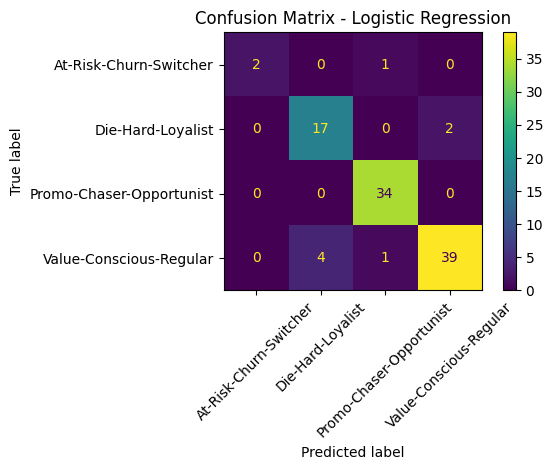


Classification Report of KNN
                          precision    recall  f1-score   support

  At-Risk-Churn-Switcher       1.00      0.33      0.50         3
       Die-Hard-Loyalist       0.64      0.47      0.55        19
Promo-Chaser-Opportunist       0.78      0.74      0.76        34
 Value-Conscious-Regular       0.60      0.73      0.66        44

                accuracy                           0.67       100
               macro avg       0.76      0.57      0.62       100
            weighted avg       0.68      0.67      0.67       100



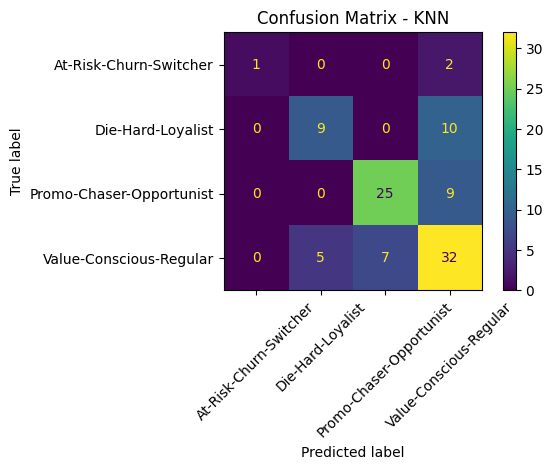


Classification Report of SVM
                          precision    recall  f1-score   support

  At-Risk-Churn-Switcher       0.00      0.00      0.00         3
       Die-Hard-Loyalist       0.78      0.74      0.76        19
Promo-Chaser-Opportunist       0.86      0.94      0.90        34
 Value-Conscious-Regular       0.78      0.80      0.79        44

                accuracy                           0.81       100
               macro avg       0.61      0.62      0.61       100
            weighted avg       0.78      0.81      0.80       100



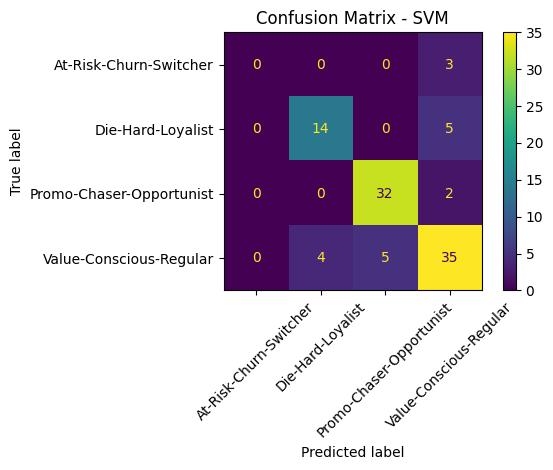


Classification Report of Decision Tree
                          precision    recall  f1-score   support

  At-Risk-Churn-Switcher       1.00      1.00      1.00         3
       Die-Hard-Loyalist       1.00      1.00      1.00        19
Promo-Chaser-Opportunist       1.00      0.94      0.97        34
 Value-Conscious-Regular       0.96      1.00      0.98        44

                accuracy                           0.98       100
               macro avg       0.99      0.99      0.99       100
            weighted avg       0.98      0.98      0.98       100



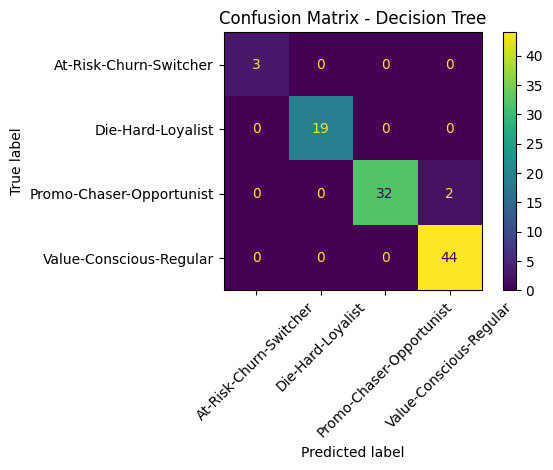

In [ ]:
for name, (model, predictions) in models_predictions.items():
    print("\n", "=" * 60)
    print("Classification Report of", name)
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=model.classes_)

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )

    display_cm.plot(xticks_rotation=45)
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

6.3 Compare model accuracy visually

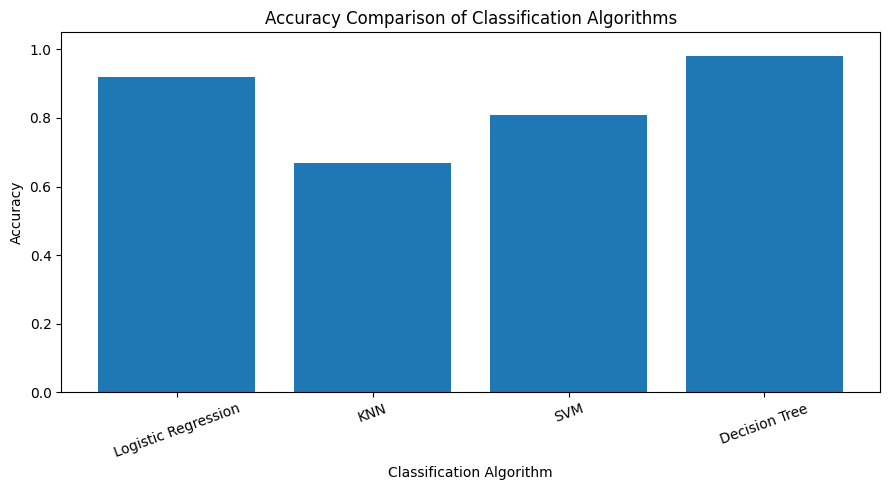

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(results_df['Model'], results_df['Accuracy'])
plt.title("Accuracy Comparison of Classification Algorithms")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

6.4 Visualize the Decision Tree

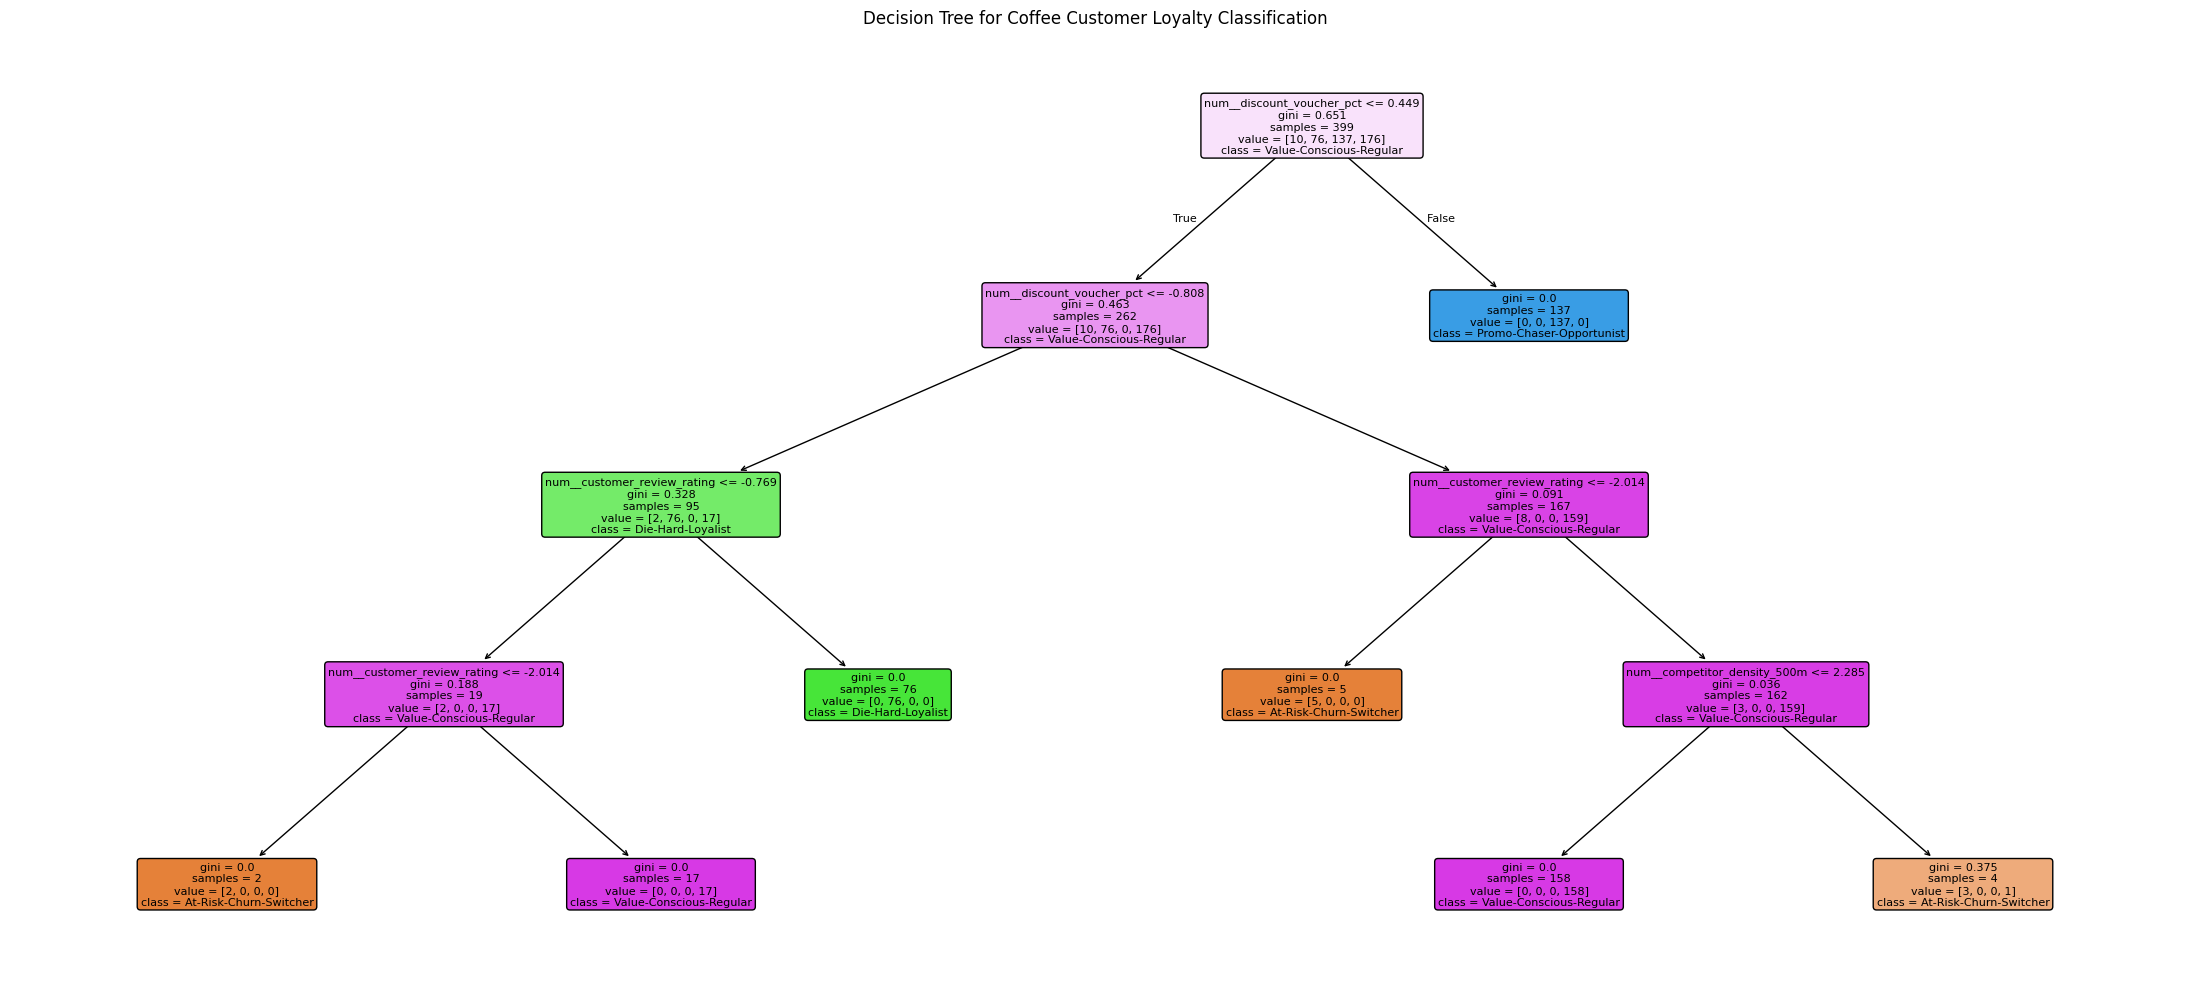

In [ ]:
from sklearn import tree

# Get the trained Decision Tree model
trained_tree = dt.named_steps['model']

# Get feature names after preprocessing
feature_names = dt.named_steps[
    'preprocessor'
].get_feature_names_out()

class_names = [str(c) for c in trained_tree.classes_]

plt.figure(figsize=(22, 10))

tree.plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Coffee Customer Loyalty Classification")
plt.tight_layout()
plt.show()

6.5 Display feature importance

Top 10 Important Features:


,Feature,Importance
2,num__discount_voucher_pct,0.826232
4,num__customer_review_rating,0.156763
0,num__competitor_density_500m,0.017005
1,num__base_price_idr,0.000000
3,num__daily_cups_sold,0.000000
5,num__dwell_time_minutes,0.000000
6,num__net_discounted_price_idr,0.000000
7,num__daily_revenue_estimate_idr,0.000000
8,num__revenue_per_competitor_density,0.000000
9,num__price_competitiveness_ratio,0.000000


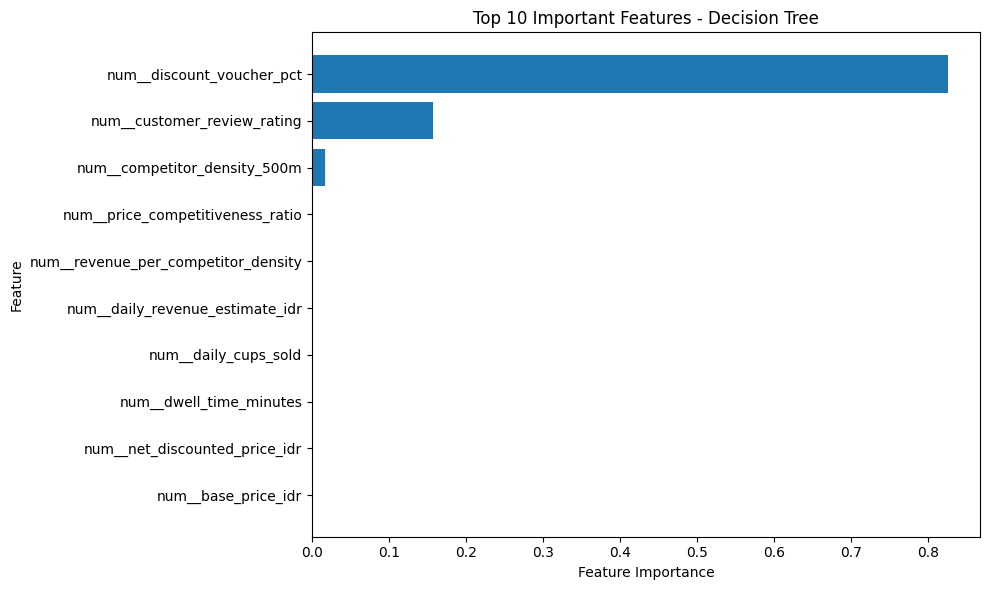

In [ ]:
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': trained_tree.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 Important Features:")
display(importance_df.head(10))

plt.figure(figsize=(10, 6))

top_features = importance_df.head(10).sort_values(
    by='Importance'
)

plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - Decision Tree")
plt.tight_layout()
plt.show()

In [ ]:
Performance Metrics Comparision

Perfo

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

models_predictions = {
    'Logistic Regression': (logreg, y_pred_logreg),
    'KNN': (knn, y_pred_knn),
    'SVM': (svm, y_pred_svm),
    'Decision Tree': (dt, y_pred_dt)
}

results = []

for name, (model, predictions) in models_predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, predictions, average='weighted', zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Performance Comparison of Classification Algorithms")
display(results_df.round(3))

Performance Comparison of Classification Algorithms


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.92,0.923,0.92,0.920
1,KNN,0.67,0.683,0.67,0.667
2,SVM,0.81,0.784,0.81,0.796
3,Decision Tree,0.98,0.981,0.98,0.980


**Result Analysis**
1. Logistic Regression: Achieved 92% accuracy, 0.923 precision, 0.92 recall, and 0.920 F1-score, showing good overall performance.

2. KNN: Achieved 67% accuracy, with 0.683 precision, 0.67 recall, and 0.667 F1-score. It showed the lowest performance among all four models.

3. SVM: Achieved 81% accuracy, 0.784 precision, 0.81 recall, and 0.796 F1-score, showing moderate performance.

4. Decision Tree: Achieved the highest accuracy of 98%, with 0.981 precision, 0.98 recall, and 0.980 F1-score, making it the best-performing model.

**Conclusion**

The project has successfully demonstrated the application of four machine learning classification algorithms: Logistic Regression, K-Nearest Neighbours (KNN), Support Vector Machine (SVM), and Decision Tree on the coffee chain sales dataset. The performance of each model was evaluated using accuracy, precision, recall, and F1-score. Among the four models, Decision Tree achieved the highest accuracy of 98%, making it the most suitable model among those tested for this classification task. Logistic Regression also performed well with 92% accuracy, while SVM achieved 81% and KNN achieved 67%. These results show how machine learning can be used to classify data, identify patterns, and support better understanding of sales information. Thus, the project successfully demonstrates how different classification algorithms can be compared to identify the model that performs best on the given dataset.